# [핸즈온 머신러닝] Chapter 3 – 분류 (Classification)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/jsmak/handson-mlp-study/blob/main/ch03/03_classification_kr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>
<br clear="left"/>

> **📚 출처 및 라이선스**
>
> - **원본 노트북**: [rickiepark/handson-mlp](https://github.com/rickiepark/handson-mlp) – [`03_classification.ipynb`](https://github.com/rickiepark/handson-mlp/blob/main/03_classification.ipynb) (박해선 님, 『핸즈온 머신러닝 with 사이킷런, 파이토치』 한빛미디어, 2026 예제 코드)
> - **원저작**: [ageron/handson-mlp](https://github.com/ageron/handson-mlp) (Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch*, O'Reilly)
> - **라이선스**: 원본 코드는 [Apache License 2.0](https://github.com/rickiepark/handson-mlp/blob/main/LICENSE)을 따릅니다.
> - **변경 사항**: 개인 학습(인프런 챌린지 복습) 목적으로 원본 노트북을 바탕으로 한국어 설명·주석을 추가하고, 셀 구성을 책의 절 번호에 맞춰 재정리했습니다. 책 본문은 포함하지 않습니다.

MNIST 손글씨 숫자 데이터셋으로 **분류(classification)** 모델을 훈련하고 평가합니다.

| 절 | 내용 | 주요 코드 |
|---|---|---|
| 3.1 | MNIST 데이터 | `fetch_openml()` |
| 3.2 | 이진 분류기 ('5' vs '5 아님') | `SGDClassifier` |
| 3.3 | 성능 측정 | `confusion_matrix`, `precision_score`, `recall_score`, `f1_score`, `precision_recall_curve`, `roc_curve` |
| 3.4 | 다중 분류 | `SVC`, `OneVsRestClassifier` |
| 3.5 | 오류 분석 | `ConfusionMatrixDisplay` |
| 3.6 | 다중 레이블 분류 | `KNeighborsClassifier`, `ClassifierChain` |
| 3.7 | 다중 출력 분류 | 잡음 제거 |

> 💡 `fetch_openml(..., as_frame=False)`로 데이터를 **넘파이 배열**로 받습니다. 데이터프레임으로 훈련한 모델에 `predict([some_digit])`처럼 넘파이 배열을 넣으면 `X does not have valid feature names` 경고가 반복해서 나오기 때문입니다. (결과값은 같습니다)

## **3.1 MNIST**

OpenML.org에서 MNIST(70,000개, 28×28 = 784픽셀)를 내려받습니다.

In [1]:
from sklearn.datasets import fetch_openml

# as_frame=False: 데이터프레임 대신 넘파이 배열로 받습니다 (feature names 경고 방지)
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist['data'], mnist['target']
X.shape, y.shape  # ((70000, 784), (70000,))

((70000, 784), (70000,))

첫 번째 이미지를 28×28로 바꿔 그리고 레이블을 확인합니다.

5


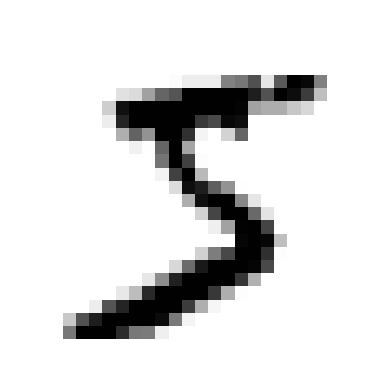

In [2]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X[0]
plot_digit(some_digit)
print(y[0])
plt.show()

처음 100개 이미지를 확인합니다.

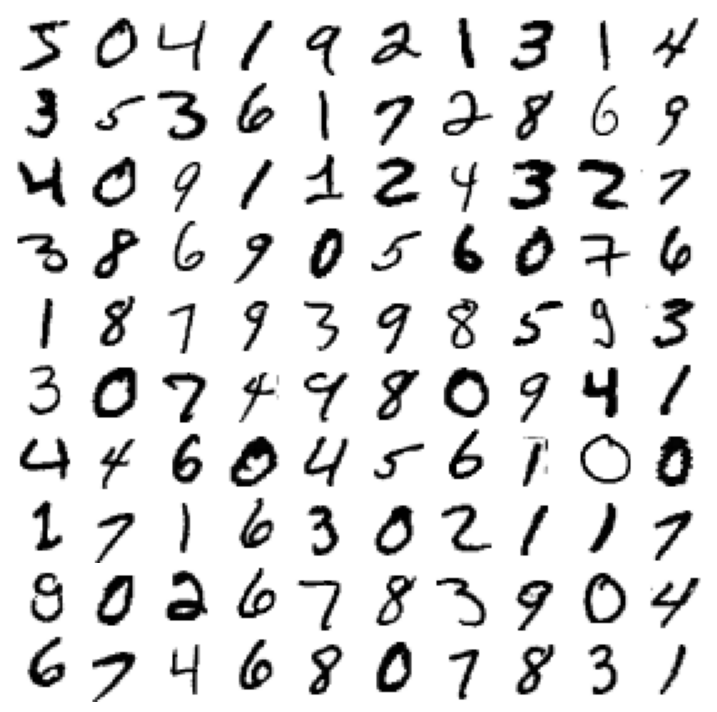

In [3]:
plt.figure(figsize=(9, 9))
for idx, image_data in enumerate(X[:100]):
    plt.subplot(10, 10, idx+1)
    plot_digit(image_data)
plt.subplots_adjust(wspace=0, hspace=0)

plt.show()

In [4]:
# 앞쪽 60,000개는 훈련 세트, 나머지 10,000개는 테스트 세트 (이미 섞여 있음)
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]
X_train.shape, X_test.shape, y_train.shape, y_test.shape  # ((60000, 784), (10000, 784), (60000,), (10000,))

((60000, 784), (10000, 784), (60000,), (10000,))

## **3.2 이진 분류기 훈련**

'5'인지 아닌지만 구분하는 **이진 분류** 타깃을 만듭니다.

In [5]:
y_train_5 = (y_train == '5')  # 5는 True이고, 다른 숫자는 모두 False
y_test_5 = (y_test == '5')

**확률적 경사 하강법(SGD)** 분류기로 훈련합니다.

In [6]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)
sgd_clf.predict([some_digit])

array([ True])

## **3.3 성능 측정**

### **3.3.1 교차 검증을 사용한 정확도 측정**

3-폴드 교차 검증으로 정확도를 측정합니다. → 95% 이상

In [7]:
from sklearn.model_selection import cross_val_score
score = cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(score.mean())
print(score)

0.9570333333333334
[0.95035 0.96035 0.9604 ]


모든 샘플을 가장 많은 클래스('5 아님')로 예측하는 더미 분류기도 정확도가 90%입니다. → **불균형 데이터에서 정확도는 좋은 지표가 아닙니다.**

In [8]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(any(dummy_clf.predict(X_train)))
score = cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(score.mean())
print(score)

False


0.90965
[0.90965 0.90965 0.90965]


### **3.3.2 혼동 행렬**

`cross_val_predict()`로 각 폴드의 예측을 모아 **혼동 행렬**을 만듭니다. (행 = 실제, 열 = 예측)

In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix 

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred)
cm

array([[53892,   687],
       [ 1891,  3530]])

In [10]:
y_train_perfect_predictions = y_train_5  # 완벽한 분류기라고 가정
confusion_matrix(y_train_5, y_train_perfect_predictions)

array([[54579,     0],
       [    0,  5421]])

### **3.3.3 정밀도와 재현율(Precision and Recall)**

정밀도 $= \frac{TP}{TP+FP}$, 재현율 $= \frac{TP}{TP+FN}$

In [11]:
from sklearn.metrics import precision_score, recall_score
print(precision_score(y_train_5, y_train_pred))  # 0.8370879772350012 = 3530 / (687 + 3530)
print(recall_score(y_train_5, y_train_pred))  # 0.6511713705958311 = 3530 / (1891 + 3530)

0.8370879772350012
0.6511713705958311


F1 점수는 정밀도와 재현율의 **조화 평균**입니다.

In [12]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred) # 0.7325171197343847

0.7325171197343847

### **3.3.4 정밀도/재현율 트레이드오프**

`decision_function()`으로 결정 점수를 얻고 임곗값을 직접 정합니다. (`SGDClassifier`의 기본 임곗값은 0)

In [13]:
y_scores = sgd_clf.decision_function([some_digit])
print(y_scores)  # [2164.22030239]

threshold = 0
y_some_digit_pred = (y_scores > threshold)
print(y_some_digit_pred) # array([ True])

[2164.22030239]
[ True]


임곗값을 3,000으로 높이면 이 '5' 이미지를 놓칩니다. → 재현율 감소

In [14]:
threshold = 3000
y_some_digit_pred = (y_scores > threshold)
print(y_some_digit_pred) # array([False])

[False]


모든 샘플의 결정 점수로 임곗값별 정밀도와 재현율을 그립니다.

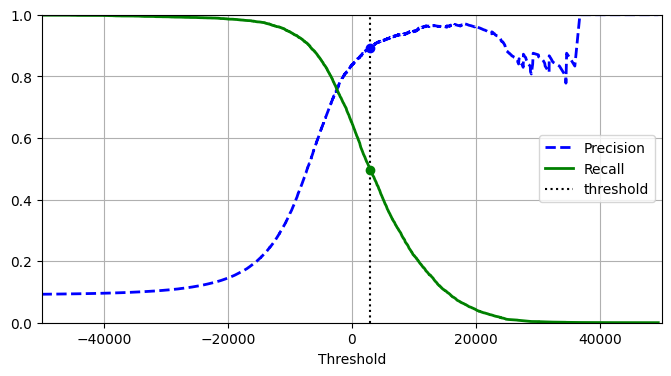

In [15]:
from sklearn.metrics import precision_recall_curve
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

plt.figure(figsize=(8, 4))  # 그래프 크기 지정 (필수 아님)
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.vlines(threshold, 0, 1.0, "k", "dotted", label="threshold")

# 임곗값 3,000 위치에 점 표시 (그래프 꾸미기)
idx = (thresholds >= threshold).argmax()  # 임곗값 이상인 첫 번째 인덱스
plt.plot(thresholds[idx], precisions[idx], "bo")
plt.plot(thresholds[idx], recalls[idx], "go")
plt.axis([-50000, 50000, 0, 1])
plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="center right")

plt.show()

재현율에 대한 정밀도(PR) 곡선입니다.

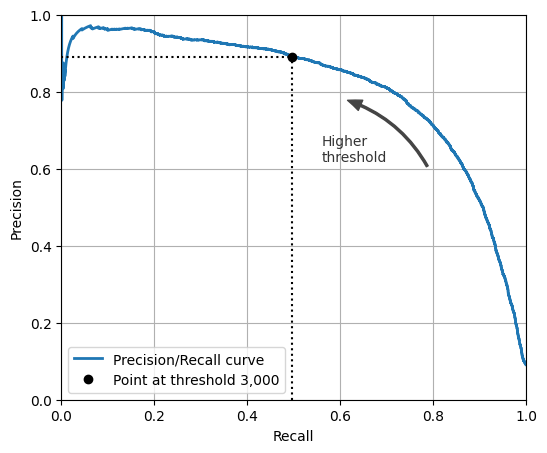

In [16]:
import matplotlib.patches as patches

plt.figure(figsize=(6, 5)) 
plt.plot(recalls, precisions, linewidth=2, label="Precision/Recall curve")

plt.plot([recalls[idx], recalls[idx]], [0., precisions[idx]], "k:")
plt.plot([0.0, recalls[idx]], [precisions[idx], precisions[idx]], "k:")
plt.plot([recalls[idx]], [precisions[idx]], "ko", label="Point at threshold 3,000")
plt.gca().add_patch(patches.FancyArrowPatch((0.79, 0.60), (0.61, 0.78), connectionstyle="arc3,rad=.2", arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10", color="#444444"))
plt.text(0.56, 0.62, "Higher\nthreshold", color="#333333")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")
plt.show()

정밀도가 90% 이상이 되는 가장 낮은 임곗값을 `argmax()`로 찾습니다.

In [17]:
idx_for_90_precision = (precisions >= 0.90).argmax()
threshold_for_90_precision = thresholds[idx_for_90_precision]
print(threshold_for_90_precision) # 3370.0194991439557
y_train_pred_90 = (y_scores >= threshold_for_90_precision)
precision_scr = precision_score(y_train_5, y_train_pred_90)
print(precision_scr) # 0.9000345901072293
recall_at_90_precision = recall_score(y_train_5, y_train_pred_90)
print(recall_at_90_precision) # 0.4799852425751706

3370.0194991439557
0.9000345901072293
0.4799852425751706


### **3.3.5 ROC 곡선**

ROC 곡선: 거짓 양성 비율(FPR)에 대한 진짜 양성 비율(TPR, 재현율)

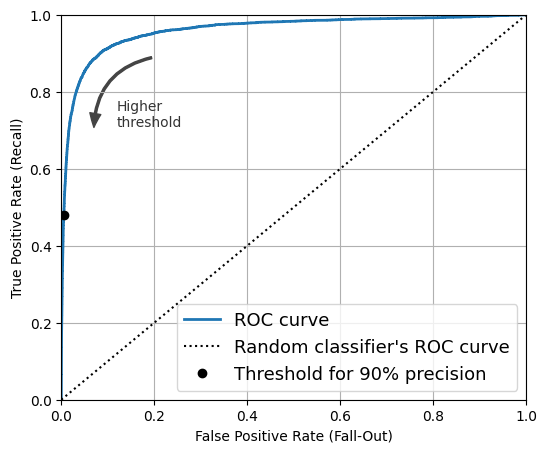

In [18]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
tpr_90, fpr_90 = tpr[idx_for_threshold_at_90], fpr[idx_for_threshold_at_90]

plt.figure(figsize=(6, 5))  # 그래프 크기 지정 (필수 아님)
plt.plot(fpr, tpr, linewidth=2, label="ROC curve")
plt.plot([0, 1], [0, 1], 'k:', label="Random classifier's ROC curve")
plt.plot([fpr_90], [tpr_90], "ko", label="Threshold for 90% precision")

plt.gca().add_patch(patches.FancyArrowPatch((0.20, 0.89), (0.07, 0.70), connectionstyle="arc3,rad=.4",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10", color="#444444"))
plt.text(0.12, 0.71, "Higher\nthreshold", color="#333333")
plt.xlabel('False Positive Rate (Fall-Out)')
plt.ylabel('True Positive Rate (Recall)')
plt.grid()
plt.axis([0, 1, 0, 1])
plt.legend(loc="lower right", fontsize=13)

plt.show()

ROC 곡선 아래 면적(AUC): 완벽한 분류기 = 1, 랜덤 분류기 = 0.5

In [19]:
from sklearn.metrics import roc_auc_score
print(roc_auc_score(y_train_5, y_scores)) # 0.9604938554008616

0.9604938554008616


⚠ **주의:** 다음 셀은 실행하는 데 몇 분이 걸릴 수 있습니다.

`RandomForestClassifier`는 `decision_function()`이 없으므로 `predict_proba()`의 양성 클래스 확률을 점수로 사용합니다.

[[0.11 0.89]
 [0.99 0.01]]


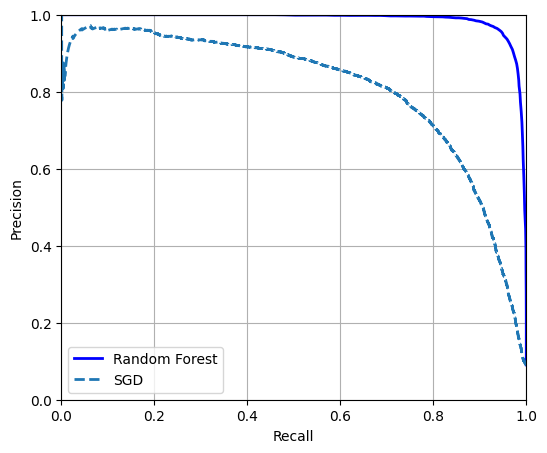

0.9274509803921569
0.9983436731328145
0.9897468089558485
0.8725327430363402


In [20]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3, method="predict_proba")
print(y_probas_forest[:2])
#[[0.11 0.89]
# [0.99 0.01]]
y_scores_forest = y_probas_forest[:, 1]
precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve( y_train_5, y_scores_forest)

plt.figure(figsize=(6, 5))
plt.plot(recalls_forest, precisions_forest, "b-", linewidth=2, label="Random Forest")
plt.plot(recalls, precisions, "--", linewidth=2, label="SGD")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")
plt.show()

y_train_pred_forest = y_probas_forest[:, 1] >= 0.5  # 양성 확률 ≥ 50%이면 양성
print(f1_score(y_train_5, y_train_pred_forest)) # 0.9274509803921569
print(roc_auc_score(y_train_5, y_scores_forest)) # 0.9983436731328145
print(precision_score(y_train_5, y_train_pred_forest)) # 0.9897468089558485
print(recall_score(y_train_5, y_train_pred_forest)) # 0.8725327430363402

## **3.4 다중 분류**

SVM은 대규모 데이터셋에서 훈련이 매우 느리므로, 처음 2,000개 샘플로만 훈련합니다.

SVC는 **OvO** 전략으로 45개의 이진 분류기를 훈련합니다.

In [21]:
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])  # y_train_5가 아니라 y_train (0~9 다중 클래스)
print(svm_clf.predict([some_digit]))
some_digit_scores = svm_clf.decision_function([some_digit])
print(some_digit_scores.round(2))
class_id = some_digit_scores.argmax()
print(class_id)
print(svm_clf.classes_)
print(svm_clf.classes_[class_id])

['5']
[[ 3.79  0.73  6.06  8.3  -0.29  9.3   1.75  2.77  7.21  4.82]]
5
['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']
5


`OneVsRestClassifier`로 **OvR** 전략을 강제하면 분류기가 10개입니다.

In [22]:
from sklearn.multiclass import OneVsRestClassifier

ovr_clf = OneVsRestClassifier(SVC(random_state=42))
ovr_clf.fit(X_train[:2000], y_train[:2000])
print(ovr_clf.predict([some_digit]))
print(len(ovr_clf.estimators_))

['5']
10


`SGDClassifier`는 OvR 전략을 사용합니다. 이 '5' 이미지를 '3'으로 잘못 예측합니다.

In [23]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train)
print(sgd_clf.predict([some_digit])) # ['3']
print(sgd_clf.decision_function([some_digit]).round()) # [[-31893. -34420.  -9531.   1824. -22320.  -1386. -26189. -16148.  -4604.  -12051.]]
print(cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")) # [0.87365 0.85835 0.8689 ]

['3']
[[-31893. -34420.  -9531.   1824. -22320.  -1386. -26189. -16148.  -4604.
  -12051.]]


[0.87365 0.85835 0.8689 ]


입력을 표준화하면 정확도가 약 89~90%로 올라갑니다.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype("float64"))
print(cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring="accuracy")) # [0.8983, 0.891 , 0.9018]

[0.8983 0.891  0.9018]


## **3.5 오류 분석**

혼동 행렬을 색으로 표시합니다.

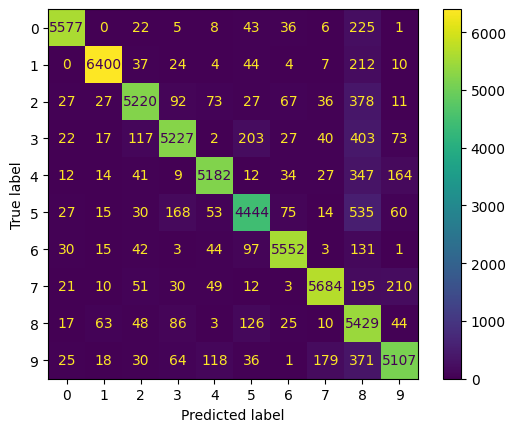

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
plt.show()

행(실제 클래스)별로 정규화하면 클래스별 정답률을 비교할 수 있습니다.

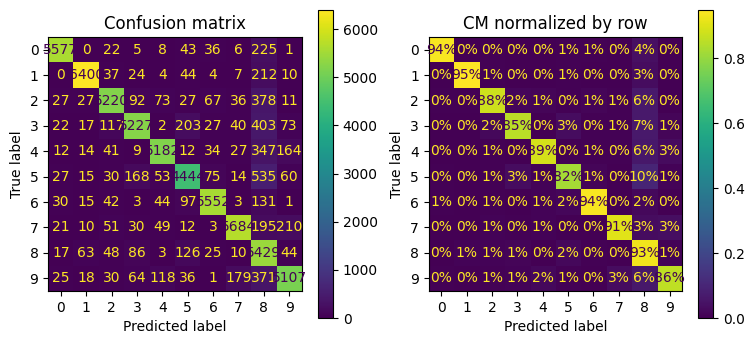

In [26]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[0])
axs[0].set_title("Confusion matrix")

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[1], normalize="true", values_format=".0%")
axs[1].set_title("CM normalized by row")

plt.show()

올바른 예측의 가중치를 0으로 두면 **오류만** 강조됩니다. (왼쪽: 행 기준, 오른쪽: 열 기준 정규화)

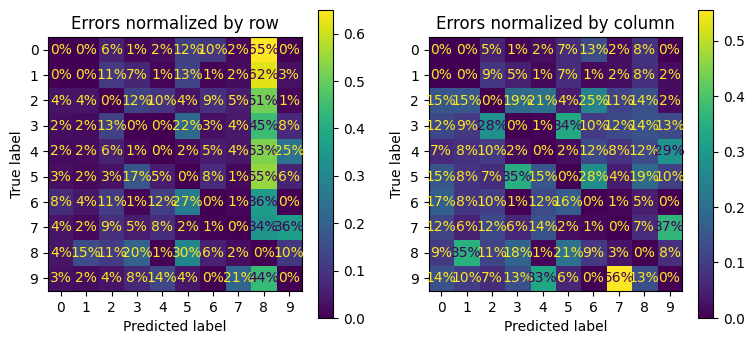

In [27]:
sample_weight = (y_train_pred != y_train)  # 올바른 예측의 가중치를 0으로 → 오류만 표시

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))
plt.rc('font', size=10)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[0], sample_weight=sample_weight,
                                        normalize="true", values_format=".0%")
axs[0].set_title("Errors normalized by row")
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[1], sample_weight=sample_weight,
                                        normalize="pred", values_format=".0%")
axs[1].set_title("Errors normalized by column")
plt.show()

3과 5의 샘플을 혼동 행렬 형태로 그려 봅니다. (왼쪽 아래·오른쪽 위 블록이 잘못 분류된 이미지)

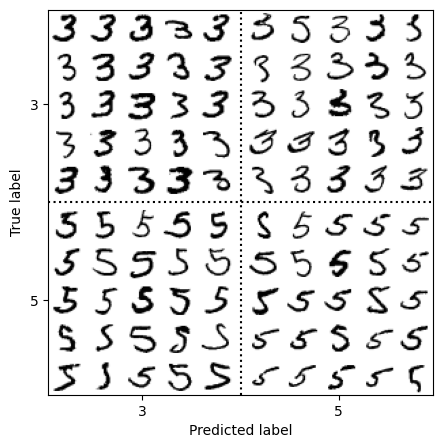

In [28]:
cl_a, cl_b = '3', '5'
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]

size = 5
pad = 0.2
plt.figure(figsize=(size, size))

for images, (label_col, label_row) in [(X_ba, (0, 0)), (X_bb, (1, 0)), (X_aa, (0, 1)), (X_ab, (1, 1))]:
    for idx, image_data in enumerate(images[:size*size]):
        # 레이블 배열 X, y와 겹치지 않도록 좌표 변수는 px, py 사용
        px = idx % size + label_col * (size + pad)
        py = idx // size + label_row * (size + pad)
        plt.imshow(image_data.reshape(28, 28), cmap="binary", extent=(px, px + 1, py, py + 1))

plt.xticks([size / 2, size + pad + size / 2], [str(cl_a), str(cl_b)])
plt.yticks([size / 2, size + pad + size / 2], [str(cl_b), str(cl_a)])
plt.plot([size + pad / 2, size + pad / 2], [0, 2 * size + pad], "k:")
plt.plot([0, 2 * size + pad], [size + pad / 2, size + pad / 2], "k:")
plt.axis([0, 2 * size + pad, 0, 2 * size + pad])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

## **3.6 다중 레이블 분류**

In [29]:
y_train[:10]  # 넘파이 문자열 배열: ['5' '0' '4' '1' '9' ...]

array(['5', '0', '4', '1', '9', '2', '1', '3', '1', '4'], dtype=object)

'큰 숫자(7, 8, 9)인가?'와 '홀수인가?' 두 레이블을 동시에 예측하는 **다중 레이블 분류**입니다.

In [30]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

y_train_large = (y_train.astype(int) >= 7)   # 큰 숫자(7, 8, 9)인가?
y_train_odd = (y_train.astype(int) % 2 == 1)  # 홀수인가?

y_multilabel = np.c_[y_train_large, y_train_odd]

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)
print(knn_clf.predict([some_digit])) # [[False  True]]

y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3)
print("F1 Score:", f1_score(y_multilabel, y_train_knn_pred, average="macro")) # F1 Score: 0.9764102655606048

[[False  True]]


F1 Score: 0.9764102655606048


`ClassifierChain`: 앞 모델의 예측을 다음 모델의 입력에 추가해 레이블 사이의 의존성을 반영합니다.

In [31]:
from sklearn.multioutput import ClassifierChain

chain_clf = ClassifierChain(SVC(), cv=3, random_state=42)
chain_clf.fit(X_train[:2000], y_multilabel[:2000])
chain_clf.predict([some_digit])

array([[0., 1.]])

## **3.7 다중 출력 분류**

MNIST 이미지에 잡음을 추가해 입력으로, 원본 이미지를 타깃으로 만듭니다. (**다중 출력 분류**: 784개 픽셀 × 0~255 값)

In [32]:
rng = np.random.default_rng(seed=42)  # 재현 가능하도록 시드 고정
noise_train = rng.integers(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise_train
noise_test = rng.integers(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise_test
y_train_mod = X_train   # 타깃 = 깨끗한 원본 이미지
y_test_mod = X_test

왼쪽: 잡음이 섞인 입력, 오른쪽: 깨끗한 타깃

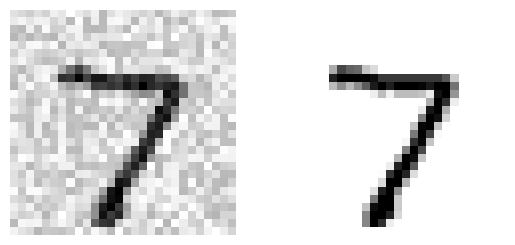

In [33]:
plt.subplot(121); plot_digit(X_test_mod[0])  # 잡음 이미지
plt.subplot(122); plot_digit(y_test_mod[0])  # 정답 이미지
plt.show()

k-최근접 이웃 분류기로 잡음을 제거합니다. (왼쪽: 예측, 오른쪽: 정답)

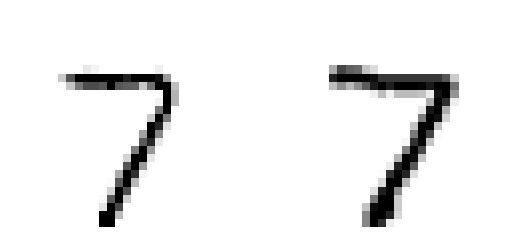

In [34]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[0]])
plt.subplot(121); plot_digit(clean_digit)
plt.subplot(122); plot_digit(y_test_mod[0])

plt.show()